In [32]:
# Imports

from pathlib import Path

import pandas as pd

import matplotlib.pyplot as plt

In [33]:
# Consts

DATASET_PATH = Path.cwd().parent / "datasets"

In [34]:
def get_college_dataset() -> pd.DataFrame:

    dataset_path = DATASET_PATH
    try:
        df = pd.read_csv(dataset_path / "College.csv")
        return df
    except OSError:
        print("Error reading the file")
        return pd.DataFrame([])

In [35]:
college = get_college_dataset()

In [36]:
college = college.rename({"Unnamed: 0": "College"}, axis = 1).set_index("College")

In [37]:
college.describe()

,Apps,Accept,Enroll,Top10perc,Top25perc,F.Undergrad,P.Undergrad,Outstate,Room.Board,Books,Personal,PhD,Terminal,S.F.Ratio,perc.alumni,Expend,Grad.Rate
count,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.000000,777.00000
mean,3001.638353,2018.804376,779.972973,27.558559,55.796654,3699.907336,855.298584,10440.669241,4357.526384,549.380952,1340.642214,72.660232,79.702703,14.089704,22.743887,9660.171171,65.46332
std,3870.201484,2451.113971,929.176190,17.640364,19.804778,4850.420531,1522.431887,4023.016484,1096.696416,165.105360,677.071454,16.328155,14.722359,3.958349,12.391801,5221.768440,17.17771
min,81.000000,72.000000,35.000000,1.000000,9.000000,139.000000,1.000000,2340.000000,1780.000000,96.000000,250.000000,8.000000,24.000000,2.500000,0.000000,3186.000000,10.00000
25%,776.000000,604.000000,242.000000,15.000000,41.000000,992.000000,95.000000,7320.000000,3597.000000,470.000000,850.000000,62.000000,71.000000,11.500000,13.000000,6751.000000,53.00000
50%,1558.000000,1110.000000,434.000000,23.000000,54.000000,1707.000000,353.000000,9990.000000,4200.000000,500.000000,1200.000000,75.000000,82.000000,13.600000,21.000000,8377.000000,65.00000
75%,3624.000000,2424.000000,902.000000,35.000000,69.000000,4005.000000,967.000000,12925.000000,5050.000000,600.000000,1700.000000,85.000000,92.000000,16.500000,31.000000,10830.000000,78.00000
max,48094.000000,26330.000000,6392.000000,96.000000,100.000000,31643.000000,21836.000000,21700.000000,8124.000000,2340.000000,6800.000000,103.000000,100.000000,39.800000,64.000000,56233.000000,118.00000


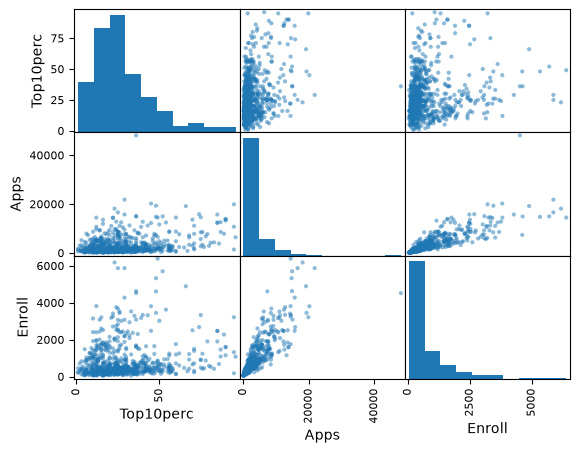

In [38]:
pd.plotting.scatter_matrix(college[['Top10perc', 'Apps', 'Enroll']])
plt.show()

In [40]:
college.columns

Index(['Private', 'Apps', 'Accept', 'Enroll', 'Top10perc', 'Top25perc',
       'F.Undergrad', 'P.Undergrad', 'Outstate', 'Room.Board', 'Books',
       'Personal', 'PhD', 'Terminal', 'S.F.Ratio', 'perc.alumni', 'Expend',
       'Grad.Rate'],
      dtype='str')

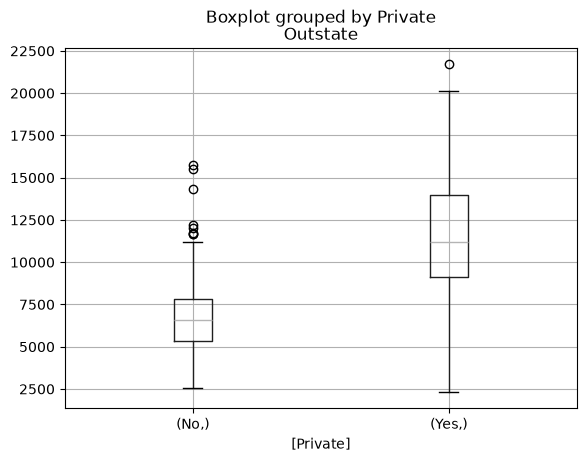

In [48]:
college.boxplot(column = ['Outstate'], by = ['Private'])
plt.show()

In [67]:
college['Elite'] = pd.cut(college['Top10perc'],
                        [0,50,100],
                        labels =['No', 'Yes'])

In [68]:
college['Elite'].value_counts()

Elite
No     699
Yes     78
Name: count, dtype: int64

<Axes: title={'center': 'Outstate'}, xlabel='[Elite]'>

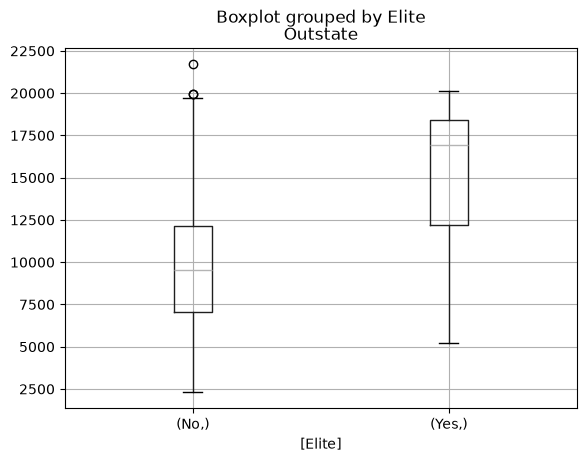

In [69]:
college.boxplot(column = ["Outstate"], by = ["Elite"])


<Axes: ylabel='Frequency'>

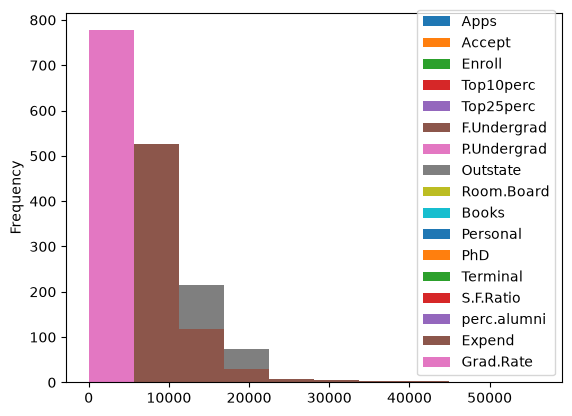

In [57]:
college.plot.hist()